# Comparação de modelos: Cats and Dogs

Treina variações do modelo fechado (`cats_and_dogs.ipynb`) para ver o efeito de cada mudança. Cada variação muda **uma coisa só** em relação à referência e roda com 3 seeds, sempre com batch 32, learning rate 0,01 e 100 épocas.

**Regras:** a comparação usa só a validação. O teste é medido uma única vez, só no vencedor. Este notebook não altera nada do `cats_and_dogs.ipynb` nem o `modelo_cats_and_dogs.pt`.

Os resultados ficam na pasta `comparacao/`. Com `TREINAR_O_QUE_FALTA = False`, nada é treinado de novo: as células só carregam o que já foi salvo.

## 1. Dados
Mesmas células do `cats_and_dogs.ipynb`, na mesma ordem e com a mesma seed, para a divisão ser idêntica.

In [1]:
import glob
import glob
import hashlib
import os
from collections import Counter, defaultdict

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from scipy.spatial import cKDTree
from torch.utils.data import DataLoader, Subset, TensorDataset

SEED = 18
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

In [2]:
import kagglehub

caminho = kagglehub.dataset_download("bhavikjikadara/dog-and-cat-classification-dataset")
print(caminho)

/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1


In [3]:
for pasta, subpastas, arquivos in os.walk(caminho):
    print(pasta, "-", len(arquivos), "arquivos")

/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1 - 0 arquivos
/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages - 0 arquivos
/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Dog - 12499 arquivos
/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Cat - 12499 arquivos


In [4]:
info = []          # um item por arquivo que abriu como imagem
nao_abriram = []   # arquivos que não abriram como imagem

for pasta, _, nomes in os.walk(caminho):
    for nome in nomes:
        arquivo = os.path.join(pasta, nome)
        try:
            with Image.open(arquivo) as img:
                img.load()
                largura, altura = img.size
                modo = img.mode
        except Exception:
            nao_abriram.append(arquivo)
            continue
        with open(arquivo, "rb") as f:
            impressao = hashlib.md5(f.read()).hexdigest()
        info.append({
            "arquivo": arquivo,
            "classe": os.path.basename(pasta),
            "largura": largura,
            "altura": altura,
            "modo": modo,
            "hash": impressao,
        })

print("Imagens que abriram:", len(info))
print("Arquivos que não abriram:", len(nao_abriram), nao_abriram[:10])
print("Pastas (classes):", Counter(d["classe"] for d in info))
print("Modos de cor:", Counter(d["modo"] for d in info))

/opt/anaconda3/envs/ambiente_aluno/lib/python3.13/site-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Imagens que abriram: 24998
Arquivos que não abriram: 0 []
Pastas (classes): Counter({'Dog': 12499, 'Cat': 12499})
Modos de cor: Counter({'RGB': 24931, 'P': 57, 'L': 5, 'CMYK': 3, 'RGBA': 2})


In [5]:
por_hash = defaultdict(list)
for d in info:
    por_hash[d["hash"]].append(d)

grupos_identicos = [g for g in por_hash.values() if len(g) > 1]
em_classes_diferentes = [g for g in grupos_identicos if len({d["classe"] for d in g}) > 1]

print("Grupos de arquivos idênticos:", len(grupos_identicos))
print("Desses, em classes diferentes:", len(em_classes_diferentes))
for g in em_classes_diferentes[:10]:
    print([d["arquivo"] for d in g])

Grupos de arquivos idênticos: 28
Desses, em classes diferentes: 2
['/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Dog/10401.jpg', '/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Dog/10797.jpg', '/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Dog/2877.jpg', '/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Cat/11565.jpg']
['/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Dog/8736.jpg', '/home/al.dulce.costa/.cache/kagglehub/datasets/bhavikjikadara/dog-and-cat-classification-dataset/versions/1/PetImages/Cat/8456.jpg']


In [6]:
assert not nao_abriram, "DECIDIR: há arquivos que não abrem como imagem."

In [7]:
# Grupos com classes diferentes saem inteiros; nos outros, fica um arquivo só.
imagens = [g[0] for g in por_hash.values() if len({d["classe"] for d in g}) == 1]

def impressao_visual(arquivo):
    # Versão 9 x 8 em cinza: cada pixel é comparado com o vizinho da direita.
    with Image.open(arquivo) as im:
        cinza = np.asarray(im.convert("L").resize((9, 8), Image.BILINEAR), dtype=np.int16)
    return (cinza[:, 1:] > cinza[:, :-1]).tobytes()

# Imagens quase idênticas ficam com a mesma origem e vão para o mesmo lado na divisão.
origens = {}
for d in imagens:
    d["origem"] = origens.setdefault(impressao_visual(d["arquivo"]), len(origens))

print("Imagens depois de tirar as repetidas:", len(imagens))
print("Origens diferentes:", len(origens))

Imagens depois de tirar as repetidas: 24966
Origens diferentes: 24962


In [8]:
# A rede precisa de pelo menos 94 px em cada lado (ver a conta no guia, D4).
imagens = [d for d in imagens if min(d["largura"], d["altura"]) >= 94]
print("Imagens com pelo menos 94 px em cada lado:", len(imagens))

menor = min(imagens, key=lambda d: d["largura"] * d["altura"])
LARGURA, ALTURA = menor["largura"], menor["altura"]
mesma_area = {(d["largura"], d["altura"]) for d in imagens
              if d["largura"] * d["altura"] == LARGURA * ALTURA}

print("Tamanho-alvo:", LARGURA, "x", ALTURA, "(largura x altura)")
print("Formatos com essa mesma área:", mesma_area)
assert len(mesma_area) == 1, "DECIDIR: há mais de um formato com a menor área."

Imagens com pelo menos 94 px em cada lado: 24822
Tamanho-alvo: 100 x 94 (largura x altura)
Formatos com essa mesma área: {(100, 94)}


In [9]:
def valor_na_posicao(img, ys, xs):
    # img: (altura, largura, 3). ys, xs: posições na imagem original, que podem ser quebradas.
    # Devolve um array (quantidade de posições, 3) com o valor de cada canal.
    h, w = img.shape[:2]
    y0 = np.clip(np.floor(ys).astype(int), 0, h - 1)
    y1 = np.clip(np.ceil(ys).astype(int), 0, h - 1)
    x0 = np.clip(np.floor(xs).astype(int), 0, w - 1)
    x1 = np.clip(np.ceil(xs).astype(int), 0, w - 1)
    # O maior valor entre os 4 pixels em volta da posição, canal por canal
    return np.max([img[y0, x0], img[y0, x1], img[y1, x0], img[y1, x1]], axis=0)

In [10]:
def redimensionar(img):
    h, w = img.shape[:2]
    # Posição, na imagem original, do centro de cada pixel da imagem nova
    ys = (np.arange(ALTURA) + 0.5) * h / ALTURA - 0.5
    xs = (np.arange(LARGURA) + 0.5) * w / LARGURA - 0.5
    yy, xx = np.meshgrid(ys, xs, indexing="ij")
    return valor_na_posicao(img, yy.ravel(), xx.ravel()).reshape(ALTURA, LARGURA, 3)

In [11]:
def girar_horario(img, graus=15):
    h, w = img.shape[:2]
    cy, cx = (h - 1) / 2, (w - 1) / 2
    t = np.deg2rad(graus)

    # Para cada pixel da imagem girada, de onde ele vem na original
    yy, xx = np.meshgrid(np.arange(h), np.arange(w), indexing="ij")
    dy, dx = yy - cy, xx - cx
    xs = dx * np.cos(t) + dy * np.sin(t) + cx
    ys = -dx * np.sin(t) + dy * np.cos(t) + cy
    dentro = (xs >= 0) & (xs <= w - 1) & (ys >= 0) & (ys <= h - 1)

    nova = np.zeros((h, w, 3), dtype=np.float32)
    nova[dentro] = valor_na_posicao(img, ys[dentro], xs[dentro])

    # Cantos vazios: média dos 3 pixels válidos mais próximos, canal por canal
    validos = np.argwhere(dentro)
    vazios = np.argwhere(~dentro)
    if len(vazios) > 0:
        _, vizinhos = cKDTree(validos).query(vazios, k=3)
        pos = validos[vizinhos]                      # (vazios, 3 vizinhos, 2 coordenadas)
        nova[vazios[:, 0], vazios[:, 1]] = nova[pos[..., 0], pos[..., 1]].mean(axis=1)
    return nova

In [12]:
def adicionar_ruido(img):
    ruidosa = img + rng.normal(0, 2, size=img.shape)
    return np.clip(ruidosa, 0, 255).astype(np.float32)

In [13]:
n = len(imagens)
ordem = rng.permutation(n)
n_rotacao = round(0.10 * n)
n_ruido = round(0.10 * n)
vao_girar = set(ordem[:n_rotacao].tolist())
vao_ruido = set(ordem[n_rotacao:n_rotacao + n_ruido].tolist())
print("Vão ganhar uma versão girada:", len(vao_girar), "| com ruído:", len(vao_ruido))

Vão ganhar uma versão girada: 2482 | com ruído: 2482


In [14]:
classes = sorted({d["classe"] for d in imagens})
X, y, grupo = [], [], []

for i, d in enumerate(imagens):
    with Image.open(d["arquivo"]) as im:
        img = np.asarray(im.convert("RGB"), dtype=np.float32)   # valores de 0 a 255

    # A rotação é feita antes de redimensionar; o ruído, depois.
    base = redimensionar(img)
    versoes = [base]
    if i in vao_girar:
        versoes.append(redimensionar(girar_horario(img)))
    elif i in vao_ruido:
        versoes.append(adicionar_ruido(base))

    for v in versoes:
        X.append(v)
        y.append(classes.index(d["classe"]))
        grupo.append(d["origem"])   # a versão nova fica com a mesma origem da original

X = torch.from_numpy(np.stack(X)).permute(0, 3, 1, 2).contiguous() / 255   # (n, 3, altura, largura), de 0 a 1
y = torch.tensor(y)
grupo = np.array(grupo)
dados = TensorDataset(X, y)

print("Classes:", classes)
print("Total de imagens (originais + novas):", len(y), "| formato:", tuple(X.shape))

Classes: ['Cat', 'Dog']
Total de imagens (originais + novas): 29786 | formato: (29786, 3, 94, 100)


In [15]:
def separar_por_grupo(indices, fracao):
    # Sorteia grupos inteiros até juntar a fração pedida das imagens.
    contagem = Counter(grupo[indices].tolist())
    alvo = round(fracao * len(indices))
    escolhidos, total = [], 0
    for g in rng.permutation(sorted(contagem)):
        if total >= alvo:
            break
        escolhidos.append(g)
        total += contagem[g]
    separado = np.isin(grupo[indices], escolhidos)
    return indices[~separado], indices[separado]

treino, teste = separar_por_grupo(np.arange(len(y)), 0.15)
treino, validacao = separar_por_grupo(treino, 0.15)

print("Treino:", len(treino), "| validação:", len(validacao), "| teste:", len(teste))

Treino: 21520 | validação: 3798 | teste: 4468


## 2. Configurações
A imagem de 224 × 224 usa as mesmas fotos e a mesma divisão. Ela só é montada quando precisa, porque ocupa cerca de 17 GB de memória.

In [16]:
import json
import matplotlib.pyplot as plt

PASTA_RES = "comparacao"
TREINAR_O_QUE_FALTA = False   # True treina as configurações que ainda não têm resultado salvo
SEEDS = [18, 19, 20]
EPOCAS, BATCH, LR = 100, 32, 0.01

# altura, largura, padding, convoluções por bloco, espelhar a imagem ao acaso no treino
CONFIGS = {
    "referencia":      dict(nome="Referência (modelo atual)",    altura=94,  largura=100, padding=1, convs=1, espelhar=False),
    "padding2":        dict(nome="Padding 2 (saída 2×3)",        altura=94,  largura=100, padding=2, convs=1, espelhar=False),
    "camadas10":       dict(nome="10 camadas convolucionais",    altura=94,  largura=100, padding=2, convs=2, espelhar=False),
    "imagem224":       dict(nome="Imagem 224×224 (saída 5×5)",   altura=224, largura=224, padding=1, convs=1, espelhar=False),
    "referencia_flip": dict(nome="Espelhamento a cada época",    altura=94,  largura=100, padding=1, convs=1, espelhar=True),
}

def criar_rede(altura, largura, padding, convs):
    blocos = []
    canais = 3
    for _ in range(5):
        for _ in range(convs):
            blocos += [nn.Conv2d(canais, 32, kernel_size=5, stride=1, padding=padding), nn.ReLU()]
            canais = 32
            altura += 2 * padding - 4
            largura += 2 * padding - 4
        blocos += [nn.MaxPool2d(kernel_size=2, stride=2), nn.Dropout(0.2)]
        altura //= 2
        largura //= 2
    return nn.Sequential(*blocos, nn.Flatten(),
                         nn.Linear(32 * altura * largura, 1024), nn.ReLU(),
                         nn.Linear(1024, 32), nn.ReLU(),
                         nn.Linear(32, 2))

In [17]:
dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
_X224 = None

def montar_224():
    # Mesmas linhas de X (célula de montagem), agora em 224 x 224. Só o sorteio do ruído muda.
    global _X224
    if _X224 is None:
        _X224 = torch.empty((len(y), 3, 224, 224))
        global ALTURA, LARGURA
        guardado = ALTURA, LARGURA
        ALTURA, LARGURA = 224, 224
        k = 0
        for i, d in enumerate(imagens):
            with Image.open(d["arquivo"]) as im:
                img = np.asarray(im.convert("RGB"), dtype=np.float32)
            base = redimensionar(img)
            versoes = [base]
            if i in vao_girar:
                versoes.append(redimensionar(girar_horario(img)))
            elif i in vao_ruido:
                versoes.append(adicionar_ruido(base))
            for v in versoes:
                _X224[k] = torch.from_numpy(v).permute(2, 0, 1) / 255
                k += 1
        ALTURA, LARGURA = guardado
        assert k == len(y)
    return _X224

def dados_de(config):
    return montar_224() if CONFIGS[config]["altura"] == 224 else X

In [18]:
def nome_arquivo(config, seed):
    return f"{PASTA_RES}/{config}_b{BATCH}_lr{LR:g}_s{seed}"

def treinar(config, seed):
    # Usa só treino e validação. O teste não entra aqui.
    c = CONFIGS[config]
    Xc = dados_de(config)
    torch.manual_seed(seed)
    m = criar_rede(c["altura"], c["largura"], c["padding"], c["convs"]).to(dispositivo)
    otim = torch.optim.SGD(m.parameters(), lr=LR)
    tr, va = torch.as_tensor(treino), torch.as_tensor(validacao)
    hist = dict(perda_treino=[], acc_treino=[], perda_val=[], acc_val=[])
    melhor_acc, melhor_ep = 0, 0
    for epoca in range(1, EPOCAS + 1):
        m.train()
        ordem_ep = tr[torch.randperm(len(tr))]
        soma, acertos = 0.0, 0
        for i in range(0, len(ordem_ep), BATCH):
            k = ordem_ep[i:i + BATCH]
            xb, yb = Xc[k].to(dispositivo), y[k].to(dispositivo)
            if c["espelhar"]:
                sorteio = torch.rand(len(k), device=dispositivo) < 0.5
                xb[sorteio] = xb[sorteio].flip(-1)
            z = m(xb)
            perda = F.cross_entropy(z, yb)
            otim.zero_grad()
            perda.backward()
            otim.step()
            soma += perda.item() * len(k)
            acertos += (z.argmax(1) == yb).sum().item()
        m.eval()
        soma_val, acertos_val = 0.0, 0
        with torch.no_grad():
            for i in range(0, len(va), 256):
                k = va[i:i + 256]
                xb, yb = Xc[k].to(dispositivo), y[k].to(dispositivo)
                z = m(xb)
                soma_val += F.cross_entropy(z, yb, reduction="sum").item()
                acertos_val += (z.argmax(1) == yb).sum().item()
        acc = acertos_val / len(va)
        hist["perda_treino"].append(soma / len(tr))
        hist["acc_treino"].append(acertos / len(tr))
        hist["perda_val"].append(soma_val / len(va))
        hist["acc_val"].append(acc)
        if acc > melhor_acc:
            melhor_acc, melhor_ep = acc, epoca
            torch.save({k: v.cpu() for k, v in m.state_dict().items()}, nome_arquivo(config, seed) + ".pt")
    resultado = dict(cfg=config, seed=seed, batch=BATCH, lr=LR, melhor_acc=melhor_acc, melhor_epoca=melhor_ep, hist=hist)
    json.dump(resultado, open(nome_arquivo(config, seed) + ".json", "w"))
    return resultado

## 3. Resultados na validação
Com `TREINAR_O_QUE_FALTA = False`, esta célula só carrega o que está salvo em `comparacao/`.

In [19]:
resultados = {}
for config in CONFIGS:
    for seed in SEEDS:
        arq = nome_arquivo(config, seed) + ".json"
        if os.path.exists(arq):
            resultados[config, seed] = json.load(open(arq))
        elif TREINAR_O_QUE_FALTA:
            resultados[config, seed] = treinar(config, seed)

def melhores(config):
    return [resultados[config, s]["melhor_acc"] for s in SEEDS if (config, s) in resultados]

media_ref = np.mean(melhores("referencia"))
print(f"{'Configuração':32s} {'seed 18':>8s} {'seed 19':>8s} {'seed 20':>8s} {'média':>7s} {'vs ref.':>8s}")
for config, c in CONFIGS.items():
    v = melhores(config)
    if not v:
        print(f"{c['nome']:32s}   ainda sem resultado")
        continue
    print(f"{c['nome']:32s} " + " ".join(f"{a:8.3f}" for a in v) + f" {np.mean(v):7.3f} {100 * (np.mean(v) - media_ref):+7.1f} p")

Configuração                      seed 18  seed 19  seed 20   média  vs ref.
Referência (modelo atual)           0.918    0.903    0.903   0.908    +0.0 p
Padding 2 (saída 2×3)               0.912    0.904    0.904   0.907    -0.1 p
10 camadas convolucionais           0.504    0.504    0.504   0.504   -40.4 p
Imagem 224×224 (saída 5×5)          0.814    0.915    0.933   0.887    -2.0 p
Espelhamento a cada época           0.921    0.919    0.919   0.920    +1.2 p


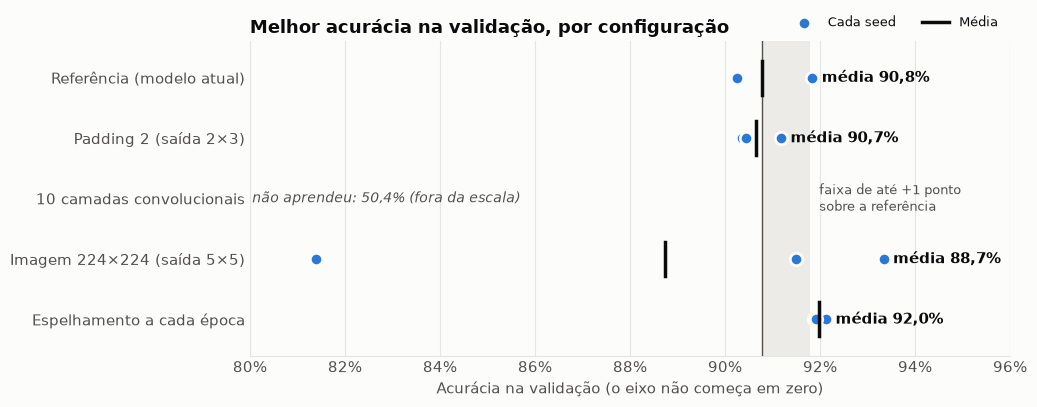

In [20]:
AZUL, CINZA, TINTA, TINTA_2, GRADE, FUNDO = "#2a78d6", "#8a8985", "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
CORES = dict(referencia="#2a78d6", padding2="#eb6834", camadas10="#1baf7a", imagem224="#eda100", referencia_flip="#e87ba4")
plt.rcParams.update({
    "figure.facecolor": FUNDO, "axes.facecolor": FUNDO, "text.color": TINTA, "axes.labelcolor": TINTA_2,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "axes.edgecolor": GRADE, "axes.grid": True,
    "grid.color": GRADE, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
virgula = lambda v, _=None: f"{100 * v:.0f}%".replace(".", ",")

ordem_cfg = list(CONFIGS)[::-1]
X_MIN, X_MAX = 0.80, 0.96
fig, ax = plt.subplots(figsize=(10.5, 4.2))
ax.axvspan(media_ref, media_ref + 0.01, color=GRADE, alpha=0.7, lw=0)
ax.axvline(media_ref, color=TINTA_2, lw=1)
ax.text(media_ref + 0.012, 2, "faixa de até +1 ponto\nsobre a referência", fontsize=9, color=TINTA_2, va="center")
for i, config in enumerate(ordem_cfg):
    v = melhores(config)
    if max(v) < X_MIN:
        ax.text(X_MIN + 0.0005, i, f"não aprendeu: {100 * np.mean(v):.1f}% (fora da escala)".replace(".", ","), va="center", fontsize=10, color=TINTA_2, style="italic")
    else:
        ax.scatter(v, [i] * len(v), s=80, color=AZUL, edgecolor=FUNDO, linewidth=2, zorder=3, label="Cada seed" if config == "referencia" else None)
        ax.plot([np.mean(v)] * 2, [i - 0.28, i + 0.28], color=TINTA, lw=2.5, zorder=4, label="Média" if config == "referencia" else None)
        ax.text(max(v) + 0.002, i, f"média {100 * np.mean(v):.1f}%".replace(".", ","), va="center", fontsize=10.5, fontweight="bold")
ax.set_yticks(range(len(ordem_cfg)), [CONFIGS[c]["nome"] for c in ordem_cfg])
ax.set_xlim(X_MIN, X_MAX)
ax.set_ylim(-0.6, len(ordem_cfg) - 0.4)
ax.set_xticks(np.arange(X_MIN, X_MAX + 0.001, 0.02))
ax.xaxis.set_major_formatter(virgula)
ax.grid(axis="y", visible=False)
ax.tick_params(length=0)
ax.set_title("Melhor acurácia na validação, por configuração")
ax.set_xlabel("Acurácia na validação (o eixo não começa em zero)")
ax.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 1), ncol=2, fontsize=9.5)
fig.tight_layout()
plt.show()

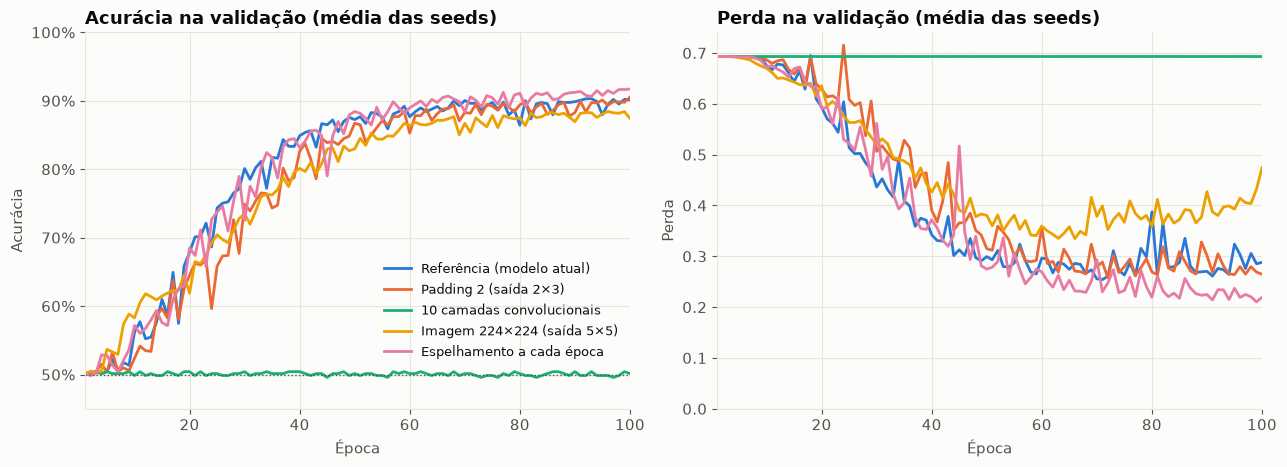

In [21]:
fig, (ax_a, ax_p) = plt.subplots(1, 2, figsize=(13, 4.8))
epocas = np.arange(1, EPOCAS + 1)
for config, c in CONFIGS.items():
    runs = [resultados[config, s]["hist"] for s in SEEDS if (config, s) in resultados]
    if not runs:
        continue
    ax_a.plot(epocas, np.mean([r["acc_val"] for r in runs], axis=0), color=CORES[config], lw=2, label=c["nome"])
    ax_p.plot(epocas, np.mean([r["perda_val"] for r in runs], axis=0), color=CORES[config], lw=2, label=c["nome"])
ax_a.axhline(0.5, color=TINTA_2, lw=1, ls=":")
ax_a.set(title="Acurácia na validação (média das seeds)", xlabel="Época", ylabel="Acurácia", xlim=(1, EPOCAS), ylim=(0.45, 1))
ax_a.yaxis.set_major_formatter(virgula)
ax_a.legend(frameon=False, loc="lower right", bbox_to_anchor=(1, 0.1), fontsize=9.5)
ax_p.set(title="Perda na validação (média das seeds)", xlabel="Época", ylabel="Perda", xlim=(1, EPOCAS), ylim=(0, None))
fig.tight_layout()
plt.show()

## 4. Efeito do tamanho do batch
Na configuração da referência, uma seed por linha. Com batch grande, a rede dá poucos passos por época e não sai de 50%, e aumentar o learning rate na mesma proporção só funcionou com batch 256. O batch maior também quase não acelerou o treino, por isso a comparação usa batch 32.

In [22]:
linhas = [json.load(open(f)) for f in glob.glob(f"{PASTA_RES}/batch/*.json")]
print(f"{'Batch':>6s} {'Learning rate':>14s} {'Melhor val.':>12s} {'Val. final':>11s}")
print(f"{32:6d} {0.01:14g} {melhores('referencia')[0]:12.3f} {resultados['referencia', 18]['hist']['acc_val'][-1]:11.3f}   (referência, seed 18)")
for d in sorted(linhas, key=lambda d: (d["batch"], d["lr"])):
    print(f"{d['batch']:6d} {d['lr']:14g} {d['melhor_acc']:12.3f} {d['hist']['acc_val'][-1]:11.3f}")

 Batch  Learning rate  Melhor val.  Val. final
    32           0.01        0.918       0.910   (referência, seed 18)
   256           0.01        0.528       0.509
   256           0.08        0.883       0.881
   512           0.01        0.557       0.504
   512           0.16        0.571       0.496
  1024           0.01        0.565       0.504
  1024           0.32        0.557       0.504
  3880           0.01        0.504       0.504
  3880           1.21        0.527       0.496


## 5. O que entra na combinação
Regra combinada: entram só as mudanças que superam a referência por mais de 1 ponto na média das seeds.

In [23]:
vencedoras = [c for c in CONFIGS if c != "referencia" and melhores(c) and np.mean(melhores(c)) > media_ref + 0.01]
print("Superaram a referência por mais de 1 ponto:", [CONFIGS[c]["nome"] for c in vencedoras])

Superaram a referência por mais de 1 ponto: ['Espelhamento a cada época']


## 6. Teste do vencedor
Só a configuração vencedora é medida no teste, na seed com a melhor validação. As outras configurações não são medidas. O resultado do teste não muda a escolha, que já foi feita pela validação.

In [24]:
assert len(vencedoras) == 1   # com duas ou mais vencedoras, a regra pediria treinar a combinação
config_final = vencedoras[0]
seed_final = max(SEEDS, key=lambda s: resultados[config_final, s]["melhor_acc"])
c = CONFIGS[config_final]

final = criar_rede(c["altura"], c["largura"], c["padding"], c["convs"]).to(dispositivo)
final.load_state_dict(torch.load(nome_arquivo(config_final, seed_final) + ".pt", weights_only=True))
final.eval()

def prever(indices):
    previsoes = []
    with torch.no_grad():
        for i in range(0, len(indices), 256):
            previsoes.append(final(X[indices[i:i + 256]].to(dispositivo)).argmax(1).cpu())
    return torch.cat(previsoes)

# Confere se os pesos e os dados deste notebook reproduzem o resultado salvo, antes de olhar o teste.
acc_val = (prever(validacao) == y[validacao]).float().mean().item()
salvo = resultados[config_final, seed_final]["melhor_acc"]
print(f"Vencedor: {c['nome']}, seed {seed_final}")
print(f"Validação recalculada: {acc_val:.4f} | salva no treino: {salvo:.4f}")
assert abs(acc_val - salvo) < 0.0005

Vencedor: Espelhamento a cada época, seed 18
Validação recalculada: 0.9213 | salva no treino: 0.9213


In [25]:
previsto_final = prever(teste)
real = y[teste]
matriz_final = np.zeros((2, 2), dtype=int)
for r_, p_ in zip(real.tolist(), previsto_final.tolist()):
    matriz_final[r_, p_] += 1

# Modelo fechado: números já medidos em cats_and_dogs.ipynb, células 20 e 22.
matriz_fechado = np.array([[1966, 232], [170, 2100]])

margem = lambda m: 1.96 * np.sqrt((m.trace() / m.sum()) * (1 - m.trace() / m.sum()) / m.sum())
print(f"{'Modelo':32s} {'acertos':>12s} {'acurácia':>9s} {'margem 95%':>11s}")
for nome, m in [("Fechado (cats_and_dogs.ipynb)", matriz_fechado), (c["nome"], matriz_final)]:
    print(f"{nome:32s} {m.trace():5d} de {m.sum():4d} {m.trace() / m.sum():9.4f} {100 * margem(m):8.1f} p")

Modelo                                acertos  acurácia  margem 95%
Fechado (cats_and_dogs.ipynb)     4066 de 4468    0.9100      0.8 p
Espelhamento a cada época         4094 de 4468    0.9163      0.8 p


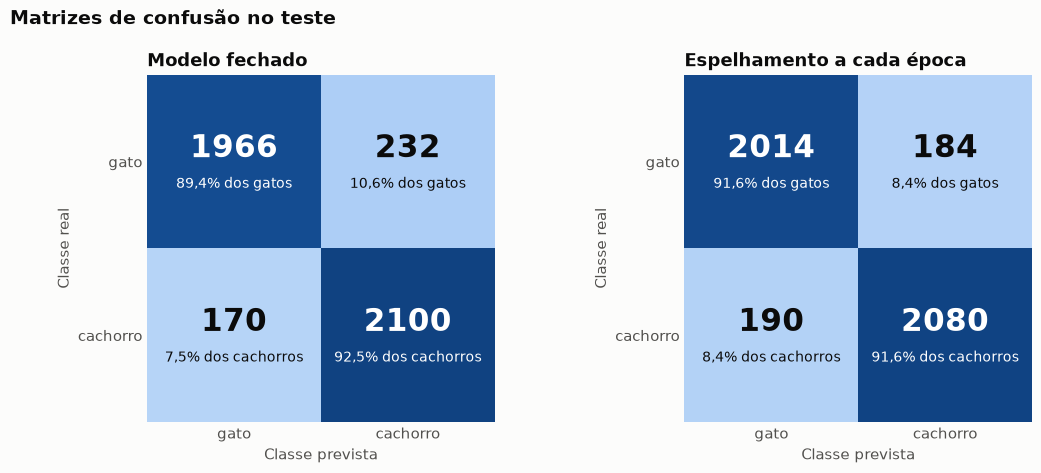

In [26]:
from matplotlib.colors import LinearSegmentedColormap
rotulos = ["gato", "cachorro"]
azuis = LinearSegmentedColormap.from_list("azuis", ["#cde2fb", "#6da7ec", "#2a78d6", "#104281"])
fig, eixos = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, m, titulo in zip(eixos, [matriz_fechado, matriz_final], ["Modelo fechado", c["nome"]]):
    ax.imshow(m, cmap=azuis, vmin=0, vmax=max(matriz_fechado.max(), matriz_final.max()))
    for i in range(2):
        for j in range(2):
            cor = "white" if m[i, j] > m.max() / 2 else TINTA
            ax.text(j, i - 0.07, f"{m[i, j]}", ha="center", va="center", color=cor, fontsize=22, fontweight="bold")
            ax.text(j, i + 0.13, f"{m[i, j] / m[i].sum():.1%} dos {rotulos[i]}s".replace(".", ","), ha="center", va="center", color=cor, fontsize=10)
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=rotulos, yticklabels=rotulos, xlabel="Classe prevista", ylabel="Classe real", title=titulo)
    ax.grid(False)
    ax.tick_params(length=0)
    for lado in ax.spines.values():
        lado.set_visible(False)
fig.suptitle("Matrizes de confusão no teste", x=0.01, ha="left", fontweight="bold", fontsize=14)
fig.tight_layout()
plt.show()

## 7. Conclusão

| Modelo | Validação | Teste |
|---|---|---|
| Fechado (`modelo_cats_and_dogs.pt`) | 90,5% | 91,0% (4066 de 4468) |
| **Espelhamento a cada época, seed 18** | **92,1%** | **91,6% (4094 de 4468)** |

- **Vencedor:** espelhamento a cada época, a única mudança que superou a referência por mais de 1 ponto na média da validação (+1,2 ponto). Pela regra combinada, ele passa a ser o modelo oficial. Os pesos estão em `comparacao/referencia_flip_b32_lr0.01_s18.pt`.
- **Combinação:** não foi treinada, porque só uma mudança venceu.
- **Teste:** a diferença de 0,6 ponto é menor que a margem de cerca de 0,8 ponto de cada medida, então o teste sozinho não comprova a melhora. O erro ficou mais equilibrado: 8,4% nas duas classes, contra 10,6% nos gatos e 7,5% nos cachorros no modelo fechado.
- **Padding 2:** não teve efeito (-0,1 ponto).
- **Imagem 224 × 224:** perdeu na média (-2,0 pontos) e foi muito instável, de 81,4% a 93,3% conforme a seed. Na seed 18, a perda de validação piorou a partir da época 46 enquanto a de treino continuava caindo, sinal de overfitting. O teste não foi medido nessa configuração.
- **10 camadas:** não aprendeu nas três seeds, com perda parada em 0,693. Isso vale para esta configuração, com SGD e learning rate 0,01, e não prova que mais camadas pioram o modelo.
- **Saída 1 × 1:** os resultados não indicam que ela fosse o principal problema, porque o padding 2 não mudou nada e a imagem maior não melhorou de forma consistente.